In [1]:
from google.colab import files
uploaded = files.upload()

Saving IT_Support_Tickets_Cleaned.csv to IT_Support_Tickets_Cleaned.csv


In [21]:
import pandas as pd

# Ensure dataset is loaded
try:
    df
except NameError:
    df = pd.read_csv('/content/IT_Support_Tickets_Cleaned.csv')

# Select text column automatically
text_col = 'clean_text' if 'clean_text' in df.columns else 'model_text'

X = df[text_col].fillna('').astype(str)
y = df['category']

# Remove records with empty text or missing target
valid = X.str.strip().ne('') & y.notna()

X = X[valid].reset_index(drop=True)
y = y[valid].reset_index(drop=True)

print("Input records:", len(X))
print("Categories:", y.nunique())
print("\nCategory distribution:")
print(y.value_counts())

Input records: 1800
Categories: 7

Category distribution:
category
Access                   409
Network                  352
Software                 338
Hardware                 282
Email & Collaboration    258
Security                 107
Other                     54
Name: count, dtype: int64


In [4]:
import pandas as pd

# Load the uploaded dataset
df = pd.read_csv('/content/IT_Support_Tickets_Cleaned.csv')

# Display basic information and the first few rows
print(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ticket_id         1800 non-null   object 
 1   created_at        1800 non-null   object 
 2   priority          1800 non-null   object 
 3   requester_dept    1762 non-null   object 
 4   model_text        1800 non-null   object 
 5   category          1800 non-null   object 
 6   assignment_group  1800 non-null   object 
 7   status            1800 non-null   object 
 8   resolution_hours  1796 non-null   float64
dtypes: float64(1), object(8)
memory usage: 126.7+ KB
None


,ticket_id,created_at,priority,requester_dept,model_text,category,assignment_group,status,resolution_hours
0,INC100000,2026-04-01 05:26:00,P4,Legal,"dns issue hi, the intranet portal doesn't load...",Network,Network Operations,Resolved,41.7
1,INC100001,2026-04-01 09:43:00,P3,HR,"account creation dear support, please set up a...",Access,Identity & Access Management,Resolved,5.3
2,INC100002,2026-04-01 10:04:00,P3,Sales,"excel closes itself good morning, excel stops ...",Software,Application Support,Resolved,12.4
3,INC100003,2026-04-01 12:18:00,P4,Operations,quota exceeded i get a mailbox almost full war...,Email & Collaboration,Messaging & Collaboration,Resolved,8.2
4,INC100004,2026-04-01 15:12:00,P3,Marketing,"new hire setup hi it, a new team member joins ...",Access,Identity & Access Management,Resolved,4.5


In [7]:
from sklearn.model_selection import StratifiedKFold

# Define X and y from the loaded df
text_col = 'clean_text' if 'clean_text' in df.columns else 'model_text'
X = df[text_col].fillna('').astype(str)
y = df['category']

# Remove records with empty text or missing target
valid = X.str.strip().ne('') & y.notna()
X = X[valid].reset_index(drop=True)
y = y[valid].reset_index(drop=True)

# Perform Stratified K-Fold Split
splitter = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1440
Testing records: 360


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

# Learn vocabulary from training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (1440, 3915)
Testing TF-IDF shape: (360, 3915)
Vocabulary size: 3915


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    "Naive Bayes": MultinomialNB(),

    "Linear SVM": CalibratedClassifierCV(
        estimator=LinearSVC(
            class_weight='balanced',
            random_state=42
        ),
        cv=3
    )
}

In [15]:
#Train and evaluate different models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    "Naive Bayes": MultinomialNB(),

    "Linear SVM": CalibratedClassifierCV(
        estimator=LinearSVC(
            class_weight='balanced',
            random_state=42
        ),
        cv=3
    )
}

results = []
trained_models = {}

# Train and evaluate each model
for name, model in models.items():

    print("\nTraining:", name)

    # Train model
    model.fit(X_train_tfidf, y_train)

    # Predict test data
    y_pred = model.predict(X_test_tfidf)

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test, y_pred,
        average='weighted',
        zero_division=0
    )

    # Store results
    results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy * 100, 2),
        'Precision': round(precision, 4),
        'Recall': round(recall, 4),
        'Macro F1': round(macro_f1, 4),
        'Weighted F1': round(weighted_f1, 4)
    })

    # Store trained models
    trained_models[name] = model

    # Classification report
    print("\nClassification Report:", name)

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

print("\nAll models trained and evaluated!")



Training: Logistic Regression

Classification Report: Logistic Regression
                       precision    recall  f1-score   support

               Access       0.95      0.90      0.93        82
Email & Collaboration       0.86      0.85      0.85        52
             Hardware       0.89      0.89      0.89        56
              Network       0.87      0.86      0.87        71
                Other       1.00      1.00      1.00        11
             Security       0.87      0.95      0.91        21
             Software       0.86      0.91      0.88        67

             accuracy                           0.89       360
            macro avg       0.90      0.91      0.90       360
         weighted avg       0.89      0.89      0.89       360


Training: Naive Bayes

Classification Report: Naive Bayes
                       precision    recall  f1-score   support

               Access       0.74      0.93      0.82        82
Email & Collaboration       0.86      0.83 

In [17]:
#Test new IT support tickets
import numpy as np

# New IT support tickets
new_tickets = [
    "Unable to connect to office VPN network",
    "Laptop screen is not turning on",
    "Outlook emails are not syncing",
    "Employee account password reset required",
    "Antivirus software showing security alert"
]

# Convert new tickets using existing TF-IDF vectorizer
new_tickets_tfidf = tfidf.transform(new_tickets)

# Confidence threshold
threshold = 0.70

# Test using all trained models
for name, model in trained_models.items():

    print("\nMODEL:", name)

    # Predict categories
    predictions = model.predict(new_tickets_tfidf)

    # Get prediction probabilities
    probabilities = model.predict_proba(new_tickets_tfidf)

    # Calculate confidence
    confidence = probabilities.max(axis=1)

    for i, ticket in enumerate(new_tickets):

        status = (
            "Auto Route"
            if confidence[i] >= threshold
            else "Manual Review"
        )

        print("\nTicket:", ticket)
        print("Predicted Category:", predictions[i])
        print("Confidence:", round(confidence[i] * 100, 2), "%")
        print("Routing Status:", status)


MODEL: Logistic Regression

Ticket: Unable to connect to office VPN network
Predicted Category: Network
Confidence: 63.06 %
Routing Status: Manual Review

Ticket: Laptop screen is not turning on
Predicted Category: Hardware
Confidence: 65.39 %
Routing Status: Manual Review

Ticket: Outlook emails are not syncing
Predicted Category: Email & Collaboration
Confidence: 77.39 %
Routing Status: Auto Route

Ticket: Employee account password reset required
Predicted Category: Access
Confidence: 86.0 %
Routing Status: Auto Route

Ticket: Antivirus software showing security alert
Predicted Category: Security
Confidence: 30.31 %
Routing Status: Manual Review

MODEL: Naive Bayes

Ticket: Unable to connect to office VPN network
Predicted Category: Network
Confidence: 73.31 %
Routing Status: Auto Route

Ticket: Laptop screen is not turning on
Predicted Category: Hardware
Confidence: 72.16 %
Routing Status: Auto Route

Ticket: Outlook emails are not syncing
Predicted Category: Email & Collaboration


In [19]:
#Compare all models
import pandas as pd

# Create comparison dataframe
comparison_df = pd.DataFrame(results)

# Sort based on Macro F1
comparison_df = comparison_df.sort_values(
    by='Macro F1',
    ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")

display(comparison_df)

# Identify best model based on Macro F1
best_model_name = comparison_df.loc[0, 'Model']

best_model = trained_models[best_model_name]

print("\nBest Model:", best_model_name)
print("Best Macro F1:", comparison_df.loc[0, 'Macro F1'])

MODEL PERFORMANCE COMPARISON


,Model,Accuracy (%),Precision,Recall,Macro F1,Weighted F1
0,Logistic Regression,89.17,0.9006,0.9091,0.9044,0.8918
1,Linear SVM,89.17,0.9020,0.9074,0.9042,0.8915
2,Naive Bayes,83.33,0.8736,0.7155,0.7456,0.8231



Best Model: Logistic Regression
Best Macro F1: 0.9044


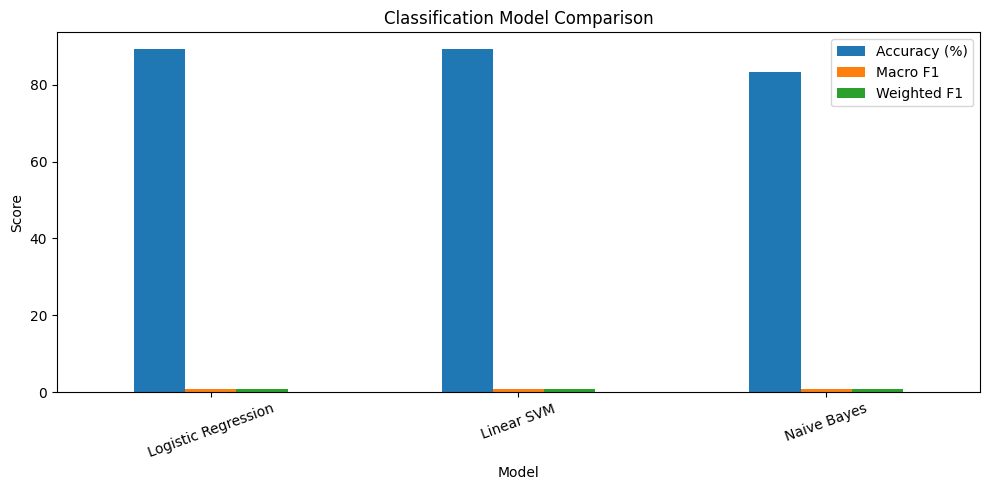

In [20]:
#Visual comparison
import matplotlib.pyplot as plt

comparison_df.set_index('Model')[
    ['Accuracy (%)', 'Macro F1', 'Weighted F1']
].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()